# Phase 7 — Explicabilité du modèle (SHAP)

**Objectif :** comprendre **pourquoi** le modèle juge un client à risque, au niveau global (quelles variables comptent) et individuel (pourquoi ce client-là). Un score sans explication n'aide pas le conseiller à choisir le bon levier de rétention.

**Plan**
1. Importance globale des variables, confrontée à l'EDA
2. Effet de chaque variable sur le risque
3. Explications individuelles
4. Limites de l'interprétation

**SHAP en deux phrases.** SHAP répartit la prédiction d'un client entre ses variables : chaque variable reçoit une **contribution** qui pousse le risque vers le haut ou vers le bas, par rapport à un client de référence. Les contributions **s'additionnent exactement** au score du modèle.

**Cas de la régression logistique.** SHAP y est **exact** (pas d'approximation) : contribution = coefficient × (valeur du client − valeur moyenne). Les contributions s'expriment en **log-odds** (logarithme de la cote `p / (1 − p)`), l'échelle sur laquelle le modèle est additif. Pour les lire : une contribution de **+0,7** multiplie la cote de départ par e^0,7 ≈ **2**.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churn.data import load_clean
from churn.eda import churn_rate_table
from churn.explain import ChurnExplainer, FEATURE_LABELS, VALUE_LABELS
from churn.features import split_data
from churn.models import load_model
from churn.viz import set_style, save_fig, fmt_pct, fmt_int, BLUE, ORANGE, AQUA, TEXT, TEXT_SECONDARY, GRID, SURFACE

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
dec = lambda v, d=2: f"{v:.{d}f}".replace(".", ",")
sigmoid = lambda z: 1 / (1 + np.exp(-z))

X_train, X_test, y_train, y_test = split_data(load_clean())
model, card = load_model("churn_model")
explainer = ChurnExplainer(model, background=X_train)   # référence : les clients d'entraînement
contrib_train = explainer.grouped_values(X_train)       # contributions par variable d'origine
print(f"{contrib_train.shape[1]} variables expliquées pour {fmt_int(len(contrib_train))} clients")
print(f"Valeur de base : {dec(explainer.base_value)} en log-odds, soit un risque de {fmt_pct(sigmoid(explainer.base_value))}")

17 variables expliquées pour 5 634 clients
Valeur de base : -1,59 en log-odds, soit un risque de 16,9 %


**À propos de la valeur de base.** C'est le score du client « moyen » (moyenne de chaque colonne), soit 16,9 % de risque, et non le taux de churn moyen (26,5 %). Les deux diffèrent parce que la moyenne est prise sur l'échelle des log-odds : la sigmoïde n'étant pas linéaire, le risque du client moyen n'est pas le risque moyen des clients. Ce n'est qu'un point de départ : seules les contributions, qui s'y ajoutent, portent l'explication.

## 1. Importance globale des variables

L'importance d'une variable = **contribution absolue moyenne** sur l'ensemble des clients : de combien, en moyenne, elle déplace le score d'un client.

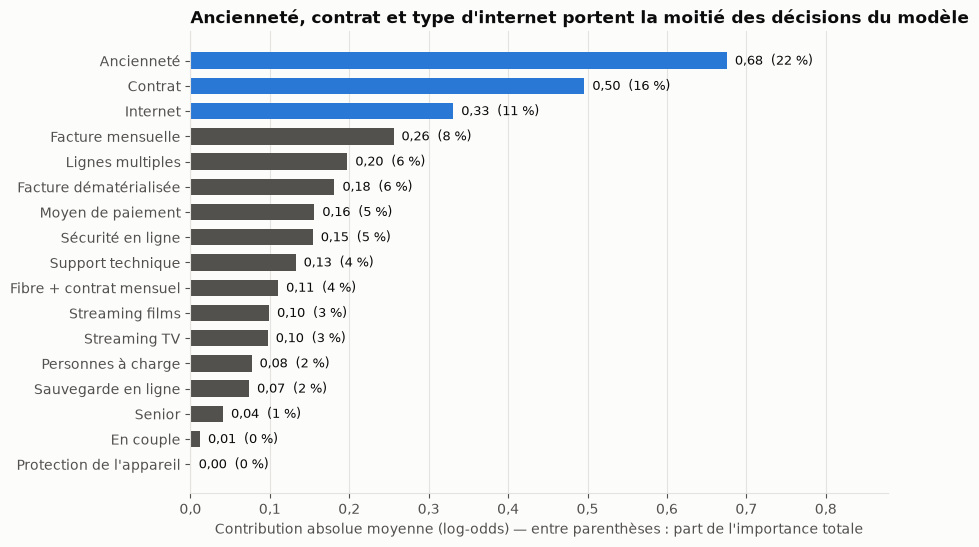

In [2]:
importance = contrib_train.abs().mean().sort_values()
labels = [FEATURE_LABELS[v] for v in importance.index]
share = importance / importance.sum()

fig, ax = plt.subplots(figsize=(9, 6))
colors = [BLUE if v in importance.index[-3:] else TEXT_SECONDARY for v in importance.index]
ax.barh(labels, importance, color=colors, height=0.65)
for i, (v, s) in enumerate(zip(importance, share)):
    ax.text(v + 0.01, i, f"{dec(v)}  ({fmt_pct(s, 0)})", va="center", fontsize=9, color=TEXT)
ax.set_xlim(0, importance.max() * 1.3)
ax.xaxis.set_major_formatter(lambda v, _: dec(v, 1))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Contribution absolue moyenne (log-odds) — entre parenthèses : part de l'importance totale")
ax.set_title("Ancienneté, contrat et type d'internet portent la moitié des décisions du modèle")
save_fig(fig, "07_importance_globale.png")
plt.show()

**Lecture :**
- Le trio **ancienneté – contrat – type d'internet** concentre **près de la moitié** de l'importance totale. On retrouve les insights n° 1, 2 et 3 de l'EDA.
- **Le genre n'apparaît pas** : il a été retiré en Phase 4 (aucun lien avec le churn).
- « Protection de l'appareil » a une importance nulle : la régularisation Elastic Net a **mis son coefficient à zéro**, car l'information est déjà portée par les autres services.

### 1.1 Effet brut (EDA) contre effet propre (modèle)

L'EDA comparait des **taux bruts** : les clients en chèque électronique partent plus, mais ils ont aussi plus souvent un contrat mensuel et peu d'ancienneté. Le modèle, lui, mesure l'effet **propre** de chaque variable, **à autres variables fixées**.

On compare les deux sur la même échelle : le **rapport de cotes** (combien de fois la cote de départ est multipliée entre deux modalités). Pour le modèle, il vaut e^(écart de contribution).

In [3]:
pairs = [  # (variable, modalité à risque, modalité de référence, libellé)
    ("Contract", "Month-to-month", "Two year", "Contrat mensuel vs 2 ans"),
    ("InternetService", "Fiber optic", "DSL", "Fibre vs DSL"),
    ("PaymentMethod", "Electronic check", "Credit card (automatic)", "Chèque électronique vs carte auto."),
    ("OnlineSecurity", "No", "Yes", "Sans vs avec sécurité en ligne"),
    ("TechSupport", "No", "Yes", "Sans vs avec support technique"),
    ("PaperlessBilling", "Yes", "No", "Facture dématérialisée vs papier"),
    ("Dependents", "No", "Yes", "Sans vs avec personnes à charge"),
    ("SeniorCitizen", "Yes", "No", "Senior vs non senior"),
]
odds = lambda r: r / (1 - r)
train_df = X_train.assign(Churn=y_train)
internet_users = train_df["InternetService"] != "No"
rows = []
for var, risky, ref, label in pairs:
    # Services optionnels : comparaison parmi les clients ayant internet (sinon « Non » mélange deux populations)
    data = train_df[internet_users] if var in ("OnlineSecurity", "TechSupport") else train_df
    rates = churn_rate_table(data, var)["churn_rate"]
    rates.index = rates.index.astype(str)
    c = contrib_train[var].groupby(X_train[var].astype(str)).mean()
    rows.append({"comparaison": label,
                 "taux brut (risque)": rates[risky], "taux brut (référence)": rates[ref],
                 "rapport de cotes brut (EDA)": odds(rates[risky]) / odds(rates[ref]),
                 "rapport de cotes propre (modèle)": np.exp(c[risky] - c[ref])})
or_table = pd.DataFrame(rows).set_index("comparaison")
or_table["part de l'effet brut conservée"] = np.log(or_table["rapport de cotes propre (modèle)"]) / np.log(or_table["rapport de cotes brut (EDA)"])
or_table.style.format({"taux brut (risque)": "{:.1%}", "taux brut (référence)": "{:.1%}",
                       "rapport de cotes brut (EDA)": "×{:.1f}", "rapport de cotes propre (modèle)": "×{:.1f}",
                       "part de l'effet brut conservée": "{:.0%}"})

,taux brut (risque),taux brut (référence),rapport de cotes brut (EDA),rapport de cotes propre (modèle),part de l'effet brut conservée
comparaison,,,,,
Contrat mensuel vs 2 ans,42.7%,2.9%,×25.3,×3.9,42%
Fibre vs DSL,42.1%,18.7%,×3.2,×1.6,41%
Chèque électronique vs carte auto.,45.7%,14.9%,×4.8,×1.4,23%
Sans vs avec sécurité en ligne,41.9%,14.4%,×4.3,×1.5,26%
Sans vs avec support technique,41.8%,15.2%,×4.0,×1.4,23%
Facture dématérialisée vs papier,33.8%,16.0%,×2.7,×1.5,38%
Sans vs avec personnes à charge,31.4%,15.2%,×2.6,×1.2,20%
Senior vs non senior,41.1%,23.7%,×2.2,×1.2,19%


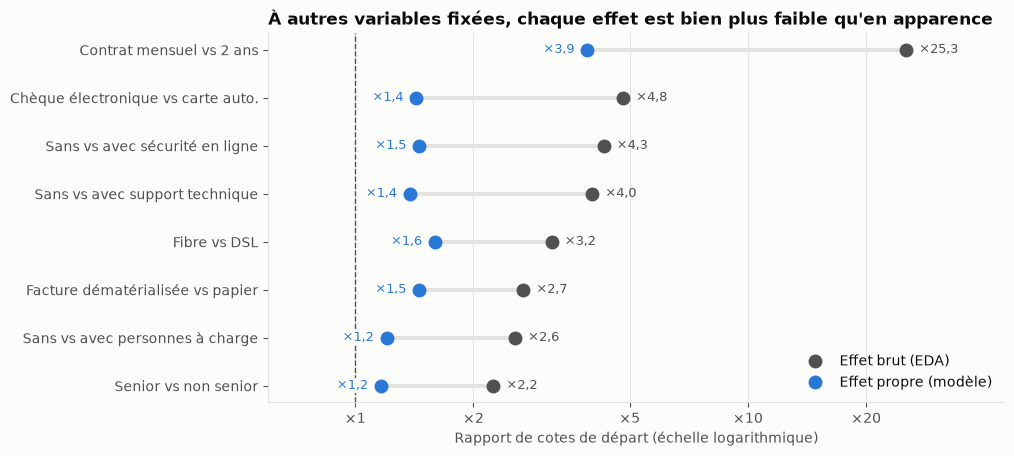

In [4]:
t = or_table.sort_values("rapport de cotes brut (EDA)")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for i, (name, row) in enumerate(t.iterrows()):
    raw, adj = row["rapport de cotes brut (EDA)"], row["rapport de cotes propre (modèle)"]
    ax.plot([adj, raw], [i, i], color=GRID, lw=3, zorder=1)
    ax.plot(raw, i, "o", markersize=9, color=TEXT_SECONDARY, zorder=2, label="Effet brut (EDA)" if i == 0 else None)
    ax.plot(adj, i, "o", markersize=9, color=BLUE, zorder=3, label="Effet propre (modèle)" if i == 0 else None)
    ax.text(raw * 1.08, i, f"×{dec(raw, 1)}", va="center", fontsize=9, color=TEXT_SECONDARY)
    ax.text(adj / 1.08, i, f"×{dec(adj, 1)}", va="center", ha="right", fontsize=9, color=BLUE, zorder=4,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(1, color=TEXT_SECONDARY, lw=1, ls="--")
ax.set_xscale("log")
ax.set_xlim(0.6, 45)
ax.set_xticks([1, 2, 5, 10, 20], ["×1", "×2", "×5", "×10", "×20"])
ax.minorticks_off()
ax.set_yticks(range(len(t)), t.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Rapport de cotes de départ (échelle logarithmique)")
ax.legend(loc="lower right")
ax.set_title("À autres variables fixées, chaque effet est bien plus faible qu'en apparence")
save_fig(fig, "07_effet_brut_vs_propre.png")
plt.show()

**Lecture :** pour chaque variable, l'effet propre (bleu) est **nettement plus faible** que l'effet brut (gris). Une grande partie de l'écart brut s'explique par d'**autres** variables qui voyagent ensemble : contrat mensuel, faible ancienneté, fibre, chèque électronique se cumulent chez les mêmes clients.

- **Contrat** : le rapport brut ×25 tombe à ×4 environ. Il reste un effet fort, mais une partie du « contrat mensuel » est en réalité de la **faible ancienneté**.
- **Senior** : l'effet brut (×2,2) **fond en grande partie** (×1,2 à autres variables fixées). Les seniors partent plus parce qu'ils ont plus souvent la fibre et un contrat mensuel, pas parce qu'ils sont seniors. **Cibler les seniors en tant que tels serait une erreur.**
- **Chèque électronique** : l'effet propre (×1,4) existe mais est modeste. Inciter au prélèvement automatique reste une piste, à valider par un test.
- **Fibre** : ×1,6 ne mesure que la variable « Internet ». La fibre agit aussi via la **facture** (plus élevée) et la feature **fibre + contrat mensuel** : son poids total est plus important. C'est une limite des comparaisons variable par variable quand les variables sont liées (voir section 4).

C'est un apport majeur du modèle par rapport à l'EDA : **démêler** des facteurs qui se cumulent.

## 2. Effet de chaque variable sur le risque

### 2.1 Variables numériques : ancienneté et facture

L'ancienneté entre dans le modèle sous deux formes (`tenure` et `log_tenure`, Phase 4) ; on additionne leurs contributions. L'axe de droite traduit la contribution en **multiplicateur de la cote de départ** par rapport au client de référence.

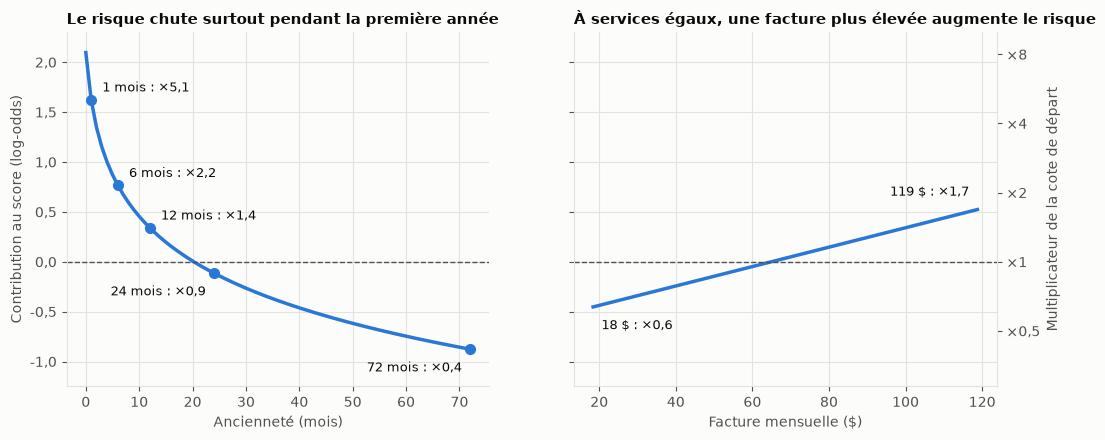

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
panels = [(axes[0], "tenure", "Ancienneté (mois)", [1, 6, 12, 24, 72]),
          (axes[1], "MonthlyCharges", "Facture mensuelle ($)", None)]
for ax, var, xlabel, marks in panels:
    order = X_train[var].sort_values().index
    ax.plot(X_train.loc[order, var], contrib_train.loc[order, var], lw=2.5, color=BLUE)
    ax.axhline(0, color=TEXT_SECONDARY, lw=1, ls="--")
    for m in marks or []:
        c = contrib_train.loc[X_train[var] == m, var].iloc[0]
        ax.plot(m, c, "o", markersize=7, color=BLUE)
        ax.annotate(f"{m} mois : ×{dec(np.exp(c), 1)}", (m, c), xytext=(8, 6) if c > 0 else (-6, -16),
                    textcoords="offset points", fontsize=9, color=TEXT, ha="left" if c > 0 else "right")
    ax.set_xlabel(xlabel)
    ax.yaxis.set_major_formatter(lambda v, _: dec(v, 1))
axes[0].set_ylabel("Contribution au score (log-odds)")
axes[0].set_ylim(-1.25, 2.3)
right = axes[1].secondary_yaxis("right", functions=(np.exp, lambda m: np.log(np.clip(m, 1e-9, None))))
right.set_yticks([0.5, 1, 2, 4, 8], ["×0,5", "×1", "×2", "×4", "×8"])
right.set_ylabel("Multiplicateur de la cote de départ")
lo, hi = X_train["MonthlyCharges"].min(), X_train["MonthlyCharges"].max()
c_lo, c_hi = (contrib_train.loc[X_train["MonthlyCharges"].idxmin(), "MonthlyCharges"],
              contrib_train.loc[X_train["MonthlyCharges"].idxmax(), "MonthlyCharges"])
axes[1].annotate(f"{lo:.0f} $ : ×{dec(np.exp(c_lo), 1)}".replace(".", ","), (lo, c_lo), xytext=(6, -16),
                 textcoords="offset points", fontsize=9, color=TEXT)
axes[1].annotate(f"{hi:.0f} $ : ×{dec(np.exp(c_hi), 1)}", (hi, c_hi), xytext=(-6, 10),
                 textcoords="offset points", fontsize=9, color=TEXT, ha="right")
axes[0].set_title("Le risque chute surtout pendant la première année", fontsize=11)
axes[1].set_title("À services égaux, une facture plus élevée augmente le risque", fontsize=11)
save_fig(fig, "07_effets_numeriques.png")
plt.show()

**Lecture :**
- **Ancienneté** : la contribution décroît très vite au début, puis lentement (forme logarithmique). Un client d'**un mois** a une cote de départ **5 fois** plus élevée que le client de référence, contre 1,4 fois à 12 mois. Entre 1 mois et 72 mois, la cote est divisée par **12**. Confirme l'insight n° 2 : **les premiers mois sont décisifs**, d'où l'intérêt d'un programme d'onboarding.
- **Facture** : l'effet est linéaire et plus modeste (de ×0,6 à ×1,7). Comme les services souscrits sont dans le modèle, il se lit « **à services égaux**, payer plus cher augmente le risque » : un signal de **sensibilité au prix**.

### 2.2 Variables catégorielles : contribution de chaque modalité

Pour une variable catégorielle, la contribution ne dépend que de la modalité du client. Orange : la modalité augmente le risque ; bleu : elle le réduit.

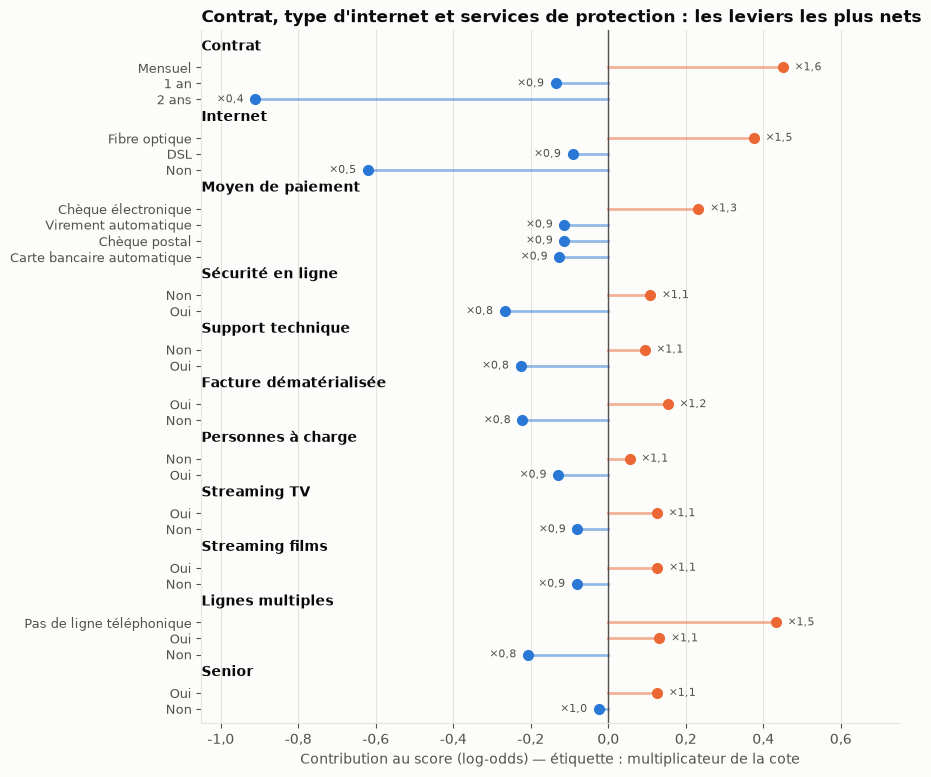

In [6]:
cat_vars = ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport",
            "PaperlessBilling", "Dependents", "StreamingTV", "StreamingMovies", "MultipleLines", "SeniorCitizen"]
rows = []
for var in cat_vars:
    c = contrib_train[var].groupby(X_train[var].astype(str)).mean()
    c = c.drop(index="No internet service", errors="ignore")  # fusionnée avec « Non » (Phase 4)
    for modality, value in c.sort_values(ascending=False).items():
        rows.append({"variable": FEATURE_LABELS[var], "modalité": VALUE_LABELS.get(modality, modality), "contribution": value})
modalities = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 9))
y, yticks, ylabels = 0, [], []
for var, grp in modalities.groupby("variable", sort=False):
    ax.text(-1.05, y - 0.15, var, fontsize=10, fontweight="bold", color=TEXT, va="bottom")
    y -= 1
    for _, r in grp.iterrows():
        color = ORANGE if r["contribution"] > 0 else BLUE
        ax.plot([0, r["contribution"]], [y, y], color=color, lw=2, alpha=0.5)
        ax.plot(r["contribution"], y, "o", markersize=7, color=color)
        ax.text(r["contribution"] + (0.03 if r["contribution"] >= 0 else -0.03), y,
                f"×{dec(np.exp(r['contribution']), 1)}", va="center", fontsize=8, color=TEXT_SECONDARY,
                ha="left" if r["contribution"] >= 0 else "right")
        yticks.append(y); ylabels.append(r["modalité"])
        y -= 1
    y -= 0.4
ax.axvline(0, color=TEXT_SECONDARY, lw=1)
ax.set_yticks(yticks, ylabels, fontsize=9)
ax.set_xlim(-1.05, 0.75)
ax.set_ylim(y + 0.5, 1.3)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: dec(v, 1))
ax.set_xlabel("Contribution au score (log-odds) — étiquette : multiplicateur de la cote")
ax.set_title("Contrat, type d'internet et services de protection : les leviers les plus nets")
save_fig(fig, "07_effets_modalites.png")
plt.show()

**Lecture :**
- **Contrat** : l'écart le plus large (de ×1,6 pour le mensuel à ×0,4 pour le 2 ans). Faire passer un client du mensuel au contrat de 2 ans divise sa cote par ~4, **à tout le reste égal**.
- **Internet** : la fibre augmente le risque, l'absence d'internet le réduit fortement (ces clients n'ont qu'une ligne téléphonique, peu d'occasions d'insatisfaction).
- **Sécurité en ligne et support technique** réduisent le risque : l'effet dose de l'insight n° 4 est confirmé, à autres variables fixées.
- **Effets contre-intuitifs** : le streaming ou les lignes multiples **augmentent** légèrement le risque, alors qu'en brut ils semblent neutres ; « pas de ligne téléphonique » (clients internet seul) ressort même à ×1,5. C'est un effet de **colinéarité** avec la facture : à facture égale, un client qui a du streaming paie moins pour le reste. Ces effets ne doivent **pas** être lus comme causaux (section 4).

### 2.3 Des explications aux leviers de rétention

Toutes les variables ne sont pas **actionnables**. On ne peut pas changer l'ancienneté d'un client, mais on peut lui proposer un autre contrat ou un service. Voici les leviers à la main de l'entreprise, avec l'effet que le modèle associe au changement :

In [7]:
levers = [
    ("Contract", "Month-to-month", "One year", "Proposer un contrat 1 an"),
    ("Contract", "Month-to-month", "Two year", "Proposer un contrat 2 ans"),
    ("OnlineSecurity", "No", "Yes", "Offrir la sécurité en ligne"),
    ("TechSupport", "No", "Yes", "Offrir le support technique"),
    ("PaymentMethod", "Electronic check", "Credit card (automatic)", "Passer au paiement automatique"),
]
lever_rows = []
for var, current, target, action in levers:
    c = contrib_train[var].groupby(X_train[var].astype(str)).mean()
    lever_rows.append({"action": action, "variation de contribution": c[target] - c[current],
                       "cote de départ multipliée par": np.exp(c[target] - c[current])})
pd.DataFrame(lever_rows).set_index("action").style.format(
    {"variation de contribution": "{:+.2f}", "cote de départ multipliée par": "×{:.2f}"})

,variation de contribution,cote de départ multipliée par
action,,
Proposer un contrat 1 an,-0.59,×0.56
Proposer un contrat 2 ans,-1.36,×0.26
Offrir la sécurité en ligne,-0.38,×0.69
Offrir le support technique,-0.32,×0.73
Passer au paiement automatique,-0.36,×0.70


**À retenir :** le levier le plus puissant est le **contrat**, suivi des **services de protection** et du **paiement automatique**. Ces effets sont des **associations** apprises sur des données historiques, pas des effets causaux garantis : un client à qui l'on **impose** un contrat 2 ans ne se comportera pas forcément comme un client qui l'a **choisi**. Chaque levier doit être **validé par un test A/B** avant d'être généralisé. L'application Streamlit (Phase 8) permettra d'explorer ces scénarios client par client (« what-if »).

## 3. Explications individuelles : pourquoi ce client ?

C'est ce que verra le conseiller dans l'application : pour un client donné, les variables qui **poussent son risque vers le haut** (orange) ou **vers le bas** (bleu), en partant du client de référence. L'axe du haut traduit le score en **probabilité de départ**.

On choisit trois clients du **jeu de test**, représentatifs des décisions de la Phase 6 :
- **Client A** : risque très élevé, contacté ;
- **Client B** : risque modéré mais **facture élevée** : contacté parce que son gain espéré est positif ;
- **Client C** : client fidèle, non contacté.

In [8]:
from churn.business import expected_gain
from churn.viz import plot_explanation

proba_test = pd.Series(model.predict_proba(X_test)[:, 1], index=X_test.index)
gain_test = pd.Series(expected_gain(proba_test, X_test["MonthlyCharges"]), index=X_test.index)

client_a = (proba_test - 0.80).abs().idxmin()
client_b = X_test.loc[(gain_test > 0) & (proba_test < 0.20), "MonthlyCharges"].idxmax()
client_c = (proba_test - 0.02).abs()[X_test["tenure"] > 60].idxmin()
clients = {"A": client_a, "B": client_b, "C": client_c}

summary = pd.DataFrame({
    name: {"customerID": cid, "risque prédit": proba_test[cid], "facture mensuelle": float(X_test.loc[cid, "MonthlyCharges"]),
           "ancienneté (mois)": X_test.loc[cid, "tenure"], "contrat": X_test.loc[cid, "Contract"],
           "gain espéré si contacté": gain_test[cid], "décision": "contacter" if gain_test[cid] > 0 else "ne pas contacter",
           "est réellement parti": "oui" if y_test[cid] == 1 else "non"}
    for name, cid in clients.items()}).T
summary.style.format({"risque prédit": "{:.1%}", "facture mensuelle": "{:.2f} $",
                      "gain espéré si contacté": "{:+.0f} $"})

,customerID,risque prédit,facture mensuelle,ancienneté (mois),contrat,gain espéré si contacté,décision,est réellement parti
A,3244-DCJWY,80.0%,70.25 $,1,Month-to-month,+152 $,contacter,oui
B,3680-CTHUH,13.6%,116.60 $,60,One year,+7 $,contacter,non
C,0123-CRBRT,2.0%,88.10 $,61,Two year,-44 $,ne pas contacter,non


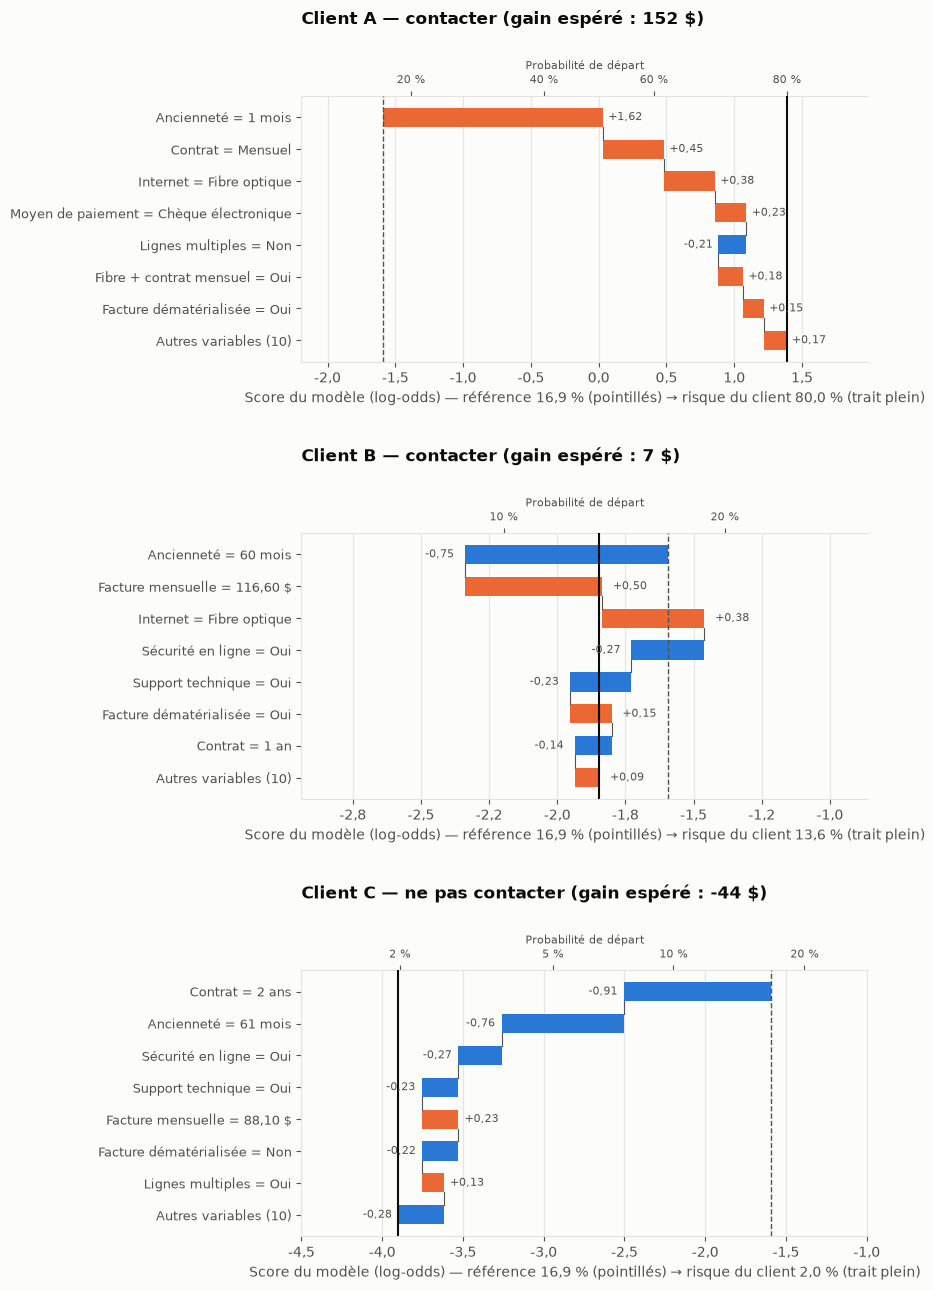

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(9, 13))
for ax, (name, cid) in zip(axes, clients.items()):
    table = explainer.explain_client(X_test.loc[[cid]])
    plot_explanation(ax, table, explainer.base_value)
    ax.set_title(f"Client {name} — {summary.loc[name, 'décision']} "
                 f"(gain espéré : {dec(summary.loc[name, 'gain espéré si contacté'], 0)} $)", pad=26)
fig.tight_layout(h_pad=3)
save_fig(fig, "07_explications_clients.png")
plt.show()

### 3.1 Traduction en langage métier

Les mêmes informations, en phrases, telles qu'elles apparaîtront dans l'application :

In [10]:
for name, cid in clients.items():
    r = explainer.reasons(X_test.loc[[cid]], top=3)
    print(f"Client {name} ({cid}) — risque {fmt_pct(proba_test[cid])} — {summary.loc[name, 'décision']}")
    print("   Facteurs de risque  :", " · ".join(r["risque"]) or "aucun notable")
    print("   Facteurs protecteurs:", " · ".join(r["protection"]) or "aucun notable")
    print()

Client A (3244-DCJWY) — risque 80,0 % — contacter
   Facteurs de risque  : Ancienneté : 1 mois · Contrat : Mensuel · Internet : Fibre optique
   Facteurs protecteurs: Lignes multiples : Non · Streaming films : Non · Streaming TV : Non

Client B (3680-CTHUH) — risque 13,6 % — contacter
   Facteurs de risque  : Facture mensuelle : 116,60 $ · Internet : Fibre optique · Facture dématérialisée : Oui
   Facteurs protecteurs: Ancienneté : 60 mois · Sécurité en ligne : Oui · Support technique : Oui

Client C (0123-CRBRT) — risque 2,0 % — ne pas contacter
   Facteurs de risque  : Facture mensuelle : 88,10 $ · Lignes multiples : Oui · Streaming films : Oui
   Facteurs protecteurs: Contrat : 2 ans · Ancienneté : 61 mois · Sécurité en ligne : Oui



**Lecture :**
- **Client A** : le cumul classique **faible ancienneté + contrat mensuel + fibre** fait exploser le risque. Levier naturel : une offre de passage en **contrat annuel**, éventuellement avec le support technique.
- **Client B** : son risque est modeste (14 %), mais sa facture élevée (117 $/mois) rend l'appel **rentable**, de justesse (+7 $ espérés) : c'est exactement le type de client que la règle du gain espéré (Phase 6) récupère et qu'un seuil unique aurait ignoré. Le conseiller sait aussi **ce qui le protège** déjà (ancienneté, sécurité en ligne, support technique) : l'argument porte plutôt sur le **prix**.
- **Client C** : ancienneté longue et contrat de 2 ans : aucun appel nécessaire, le budget est mieux employé ailleurs.

Note : certains « facteurs protecteurs » listés (lignes multiples : Non, streaming : Non) sont des effets de colinéarité avec la facture, pas des leviers (voir section 4). L'application les présentera, mais ne les proposera pas comme actions.

L'explication rend le score **actionnable** : le conseiller ne reçoit pas seulement « 80 % de risque », mais **pourquoi** et donc **quoi proposer**.